# FER2013 – CNN (PyTorch)

## Cách chạy

1. Cài dependency nếu chưa có: `pip install -r code/requirements.txt`.
2. Chạy toàn bộ cell.
3. Kết quả mới ở `Code_FER2013/outputs_<mode>_<weights>/`
   (`runs/`, `figures/`, `experiment_log.csv`, `best_report.json`); file zip ở cuối notebook.

## Code và dữ liệu

- Notebook phải được chạy từ thư mục `Code_FER2013/`.
- `CODE = ./code`, `EXP_DIR = .`, `DATA_DIR = ../` (tức `BT02/`).
- Nếu kernel có cwd khác, sửa `CODE` trong cell cấu hình thành đường dẫn tuyệt đối
  tới `.../Code_FER2013/code`; `EXP_DIR` và `DATA_DIR` tự suy ra đường dẫn.
- Dữ liệu: dùng `BT02/fer2013.npz` nếu đã có. Nếu chưa, notebook sẽ tự động tải xuống.
  `icml_face_data.csv` vào `BT02/` rồi tạo npz. Có thể đặt sẵn CSV để chạy offline.
- `EPOCHS_MODE = "long"` (mặc định): E1 20, E2–E5 25, E6 30 epoch.
  `"full"`: cấu hình báo cáo (12/12/12/12/12/10). `"quick"`: 2 epoch để chạy thử.
- `CLASS_WEIGHTS = "sqrt"`: cân bằng lớp cho Disgust/Fear; có thể đổi `"none"`/`"inverse"`.
- Augmentation mạnh hơn: xoay/dịch/zoom 12°/0.12/0.12 + random erasing p=0.25.


In [5]:
!pip uninstall torch torchvision torchaudio -y
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124

Looking in indexes: https://download.pytorch.org/whl/cu124
   ---------------------------------------- 0.0/2.5 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 GB 2.8 MB/s eta 0:14:59
   ---------------------------------------- 0.0/2.5 GB 3.2 MB/s eta 0:13:12
   ---------------------------------------- 0.0/2.5 GB 3.1 MB/s eta 0:13:49
   ---------------------------------------- 0.0/2.5 GB 3.1 MB/s eta 0:13:41
   ---------------------------------------- 0.0/2.5 GB 3.0 MB/s eta 0:13:56
   ---------------------------------------- 0.0/2.5 GB 3.0 MB/s eta 0:13:55
   ---------------------------------------- 0.0/2.5 GB 3.0 MB/s eta 0:14:04
   ---------------------------------------- 0.0/2.5 GB 2.9 MB/s eta 0:14:38
   ---------------------------------------- 0.0/2.5 GB 2.9 MB/s eta 0:14:32
   ---------------------------------------- 0.0/2.5 GB 2.8 MB/s eta 0:15:18
   ----------------------------------------

## 1. Kiểm tra môi trường

In [1]:
import sys, torch

print(torch.__version__)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA: training will use CPU.")


2.6.0+cu124
Python: 3.10.6
PyTorch: 2.6.0+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Cấu hình

In [2]:
import os
import sys

# Chạy notebook từ thư mục Code_FER2013/.
CODE = os.path.abspath("code")
EXP_DIR = os.path.dirname(CODE)
DATA_DIR = os.path.dirname(EXP_DIR)

sys.path.insert(0, CODE)  

DATA_CSV = os.path.join(DATA_DIR, "icml_face_data.csv")
DATA_NPZ = os.path.join(DATA_DIR, "fer2013.npz")

EPOCHS_MODE = "long"      # "long" | "full" | "quick"
QUICK_EPOCHS = 2
CLASS_WEIGHTS = "sqrt"    # "none" | "sqrt" | "inverse"
FORCE_RERUN = False       # True: retrain even if runs/<name>.json already exists
RUN_ANALYSIS = True

assert EPOCHS_MODE in ("long", "full", "quick")
assert CLASS_WEIGHTS in ("none", "sqrt", "inverse")

OUT_DIR = os.path.join(EXP_DIR, f"outputs_{EPOCHS_MODE}_{CLASS_WEIGHTS}")
RUNS_DIR = os.path.join(OUT_DIR, "runs")
FIG_DIR = os.path.join(OUT_DIR, "figures")
LOG_PATH = os.path.join(OUT_DIR, "experiment_log.csv")
REPORT_PATH = os.path.join(OUT_DIR, "best_report.json")
os.makedirs(OUT_DIR, exist_ok=True)

print("CODE:", CODE)
print("EXP_DIR:", EXP_DIR)
print("DATA_NPZ:", DATA_NPZ)
print("EPOCHS_MODE:", EPOCHS_MODE)
print("CLASS_WEIGHTS:", CLASS_WEIGHTS)
print("OUT_DIR:", OUT_DIR)


CODE: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\code
EXP_DIR: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013
DATA_NPZ: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\fer2013.npz
EPOCHS_MODE: long
CLASS_WEIGHTS: sqrt
OUT_DIR: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\outputs_long_sqrt


## 3. Kiểm tra code local

In [3]:
import os

print("Using local code:", CODE)
print("Files:", sorted(os.listdir(CODE)))
assert os.path.isfile(os.path.join(CODE, "fer", "config.py")), f"Không thấy code tại {CODE}"
assert os.path.isfile(os.path.join(CODE, "train.py"))
assert os.path.isfile(os.path.join(CODE, "analyze.py"))


Using local code: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\code
Files: ['analyze.py', 'fer', 'fer_lib.py', 'prepare_data.py', 'requirements.txt', 'run_all.sh', 'run_rest.sh', 'train.py']


## 4. Dữ liệu FER2013

In [4]:
import json, os, urllib.request

OID = "2c7ce224ef03ec2e2e522d10b93a069900b26fa1c028174d91d5f1f8013a2884"
SIZE = 301072768
REPO = "kelacloiloilac/Thuchanhvabaitapdeeplearning"


def download_lfs(oid, size, dest):
    payload = {"operation": "download", "transfers": ["basic"],
               "objects": [{"oid": oid, "size": size}]}
    url = f"https://github.com/{REPO}.git/info/lfs/objects/batch"
    headers = {"Accept": "application/vnd.git-lfs+json",
               "Content-Type": "application/vnd.git-lfs+json"}
    req = urllib.request.Request(url, data=json.dumps(payload).encode("utf-8"),
                                 headers=headers, method="POST")
    with urllib.request.urlopen(req, timeout=120) as r:
        info = json.load(r)
    href = info["objects"][0]["actions"]["download"]["href"]
    total = 0
    with urllib.request.urlopen(href, timeout=300) as resp, open(dest, "wb") as f:
        while True:
            chunk = resp.read(1 << 20)
            if not chunk:
                break
            f.write(chunk)
            total += len(chunk)
    return total


if os.path.exists(DATA_NPZ) and os.path.getsize(DATA_NPZ) > 1_000_000:
    print("Existing npz found; skip CSV download:", DATA_NPZ)
else:
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists(DATA_CSV) and os.path.getsize(DATA_CSV) == SIZE:
        print("Dataset already present:", DATA_CSV)
    else:
        try:
            got = download_lfs(OID, SIZE, DATA_CSV)
            print("Downloaded", got, "bytes to", DATA_CSV)
        except Exception as e:
            raise RuntimeError(
                "Không tải được dữ liệu. Hãy đặt file icml_face_data.csv (FER2013) "
                f"vào {DATA_CSV} rồi chạy lại cell này."
            ) from e

    print("CSV size:", os.path.getsize(DATA_CSV))
    assert os.path.getsize(DATA_CSV) == SIZE, "Unexpected CSV size"


Existing npz found; skip CSV download: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\fer2013.npz


## 5. Tạo `fer2013.npz`

In [5]:
import os, subprocess, sys

if os.path.exists(DATA_NPZ) and os.path.getsize(DATA_NPZ) > 1_000_000:
    print("Using existing", DATA_NPZ)
else:
    subprocess.run([sys.executable, "prepare_data.py", "--csv", DATA_CSV, "--out", DATA_NPZ],
                   cwd=CODE, check=True)

print("NPZ:", DATA_NPZ, os.path.getsize(DATA_NPZ), "bytes")


Using existing c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\fer2013.npz
NPZ: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\fer2013.npz 78318303 bytes


## 6. Huấn luyện E1–E6

In [6]:
import json, os, subprocess, sys, time, torch

from fer.experiments import EXPERIMENTS

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Training device:", DEVICE)
if DEVICE == "cpu" and EPOCHS_MODE in ("full", "long"):
    print("No CUDA: this mode can be slow on CPU; use EPOCHS_MODE = 'quick' for a smoke test.")

runs_dir = RUNS_DIR
os.makedirs(runs_dir, exist_ok=True)
env = os.environ.copy()
env["PYTHONUNBUFFERED"] = "1"
t_start = time.time()

for cfg in EXPERIMENTS:
    name = cfg["name"]
    out_json = os.path.join(runs_dir, name + ".json")
    pt_path = os.path.join(runs_dir, name + ".pt")
    default_epochs = cfg.get("epochs", 15)
    if EPOCHS_MODE == "long":
        epochs = cfg.get("long_epochs", default_epochs)
    elif EPOCHS_MODE == "full":
        epochs = default_epochs
    else:
        epochs = min(default_epochs, QUICK_EPOCHS)
    want = dict(arch=cfg.get("arch", "small"), aug=cfg.get("aug", 1), epochs=epochs,
                lr=cfg.get("lr", 1e-3), opt=cfg.get("opt", "adam"),
                sched=cfg.get("sched", "none"), bs=cfg.get("bs", 64),
                wd=cfg.get("wd", 0.0), ls=cfg.get("ls", 0.0), device=DEVICE,
                class_weights=CLASS_WEIGHTS)
    if os.path.exists(out_json) and os.path.exists(pt_path) and not FORCE_RERUN:
        try:
            prev = json.load(open(out_json)).get("args", {})
        except Exception:
            prev = {}
        if all(prev.get(k) == v for k, v in want.items()):
            print("[skip]", name, "- matches", want)
            continue
        print("[retrain]", name, "| existing", {k: prev.get(k) for k in want},
              "-> requested", want)
    cmd = [sys.executable, "train.py", "--name", name,
           "--arch", cfg.get("arch", "small"), "--aug", str(cfg.get("aug", 1)),
           "--epochs", str(epochs), "--device", DEVICE,
           "--class-weights", CLASS_WEIGHTS,
           "--data", DATA_NPZ, "--out", runs_dir]
    for key in ("lr", "opt", "sched", "bs", "wd", "ls"):
        if key in cfg:
            cmd += [f"--{key}", str(cfg[key])]
    print("=" * 78)
    print("RUN", name, "| epochs", epochs, "| weights", CLASS_WEIGHTS, "| device", DEVICE)
    print("=" * 78, flush=True)
    t0 = time.time()
    subprocess.run(cmd, cwd=CODE, check=True, env=env)
    print(f"[done] {name} in {(time.time() - t0) / 60:.1f} min", flush=True)

print(f"All requested experiments finished in {(time.time() - t_start) / 60:.1f} min")


Training device: cuda
RUN E1_small_noaug | epochs 20 | weights sqrt | device cuda
[done] E1_small_noaug in 1.5 min
RUN E2_small_aug | epochs 25 | weights sqrt | device cuda
[done] E2_small_aug in 2.5 min
RUN E3_small_aug_onecycle | epochs 25 | weights sqrt | device cuda
[done] E3_small_aug_onecycle in 2.7 min
RUN E4_small_nobn_aug | epochs 25 | weights sqrt | device cuda
[done] E4_small_nobn_aug in 2.8 min
RUN E5_small_sgd_onecycle | epochs 25 | weights sqrt | device cuda
[done] E5_small_sgd_onecycle in 2.6 min
RUN E6_medium_aug_onecycle | epochs 30 | weights sqrt | device cuda
[done] E6_medium_aug_onecycle in 5.4 min
All requested experiments finished in 17.4 min


## 7. Phân tích, confusion matrix, filter

In [7]:
import subprocess, sys

if RUN_ANALYSIS:
    subprocess.run([sys.executable, "analyze.py",
                    "--runs", RUNS_DIR,
                    "--figures", FIG_DIR,
                    "--data", DATA_NPZ,
                    "--log", LOG_PATH,
                    "--report", REPORT_PATH], cwd=CODE, check=True)
    print("Analysis done:", OUT_DIR)
else:
    print("RUN_ANALYSIS is False; skipped")


Analysis done: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\outputs_long_sqrt


## 8. Hiển thị kết quả

## Experiment log

| Thí nghiệm | Kiến trúc | Số tham số | Augmentation | Optimizer | LR | Scheduler | Weight decay | Label smoothing | Class weights | Epochs | Best epoch | Train acc @best | Val loss @best | Val acc (PublicTest) | Test acc (PrivateTest) | Thời gian (phút) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| E1_small_noaug | small | 615399 | không | adam | 0.001 | none | 0.0 | 0.0 | sqrt | 20 | 20 | 0.4849 | 1.2005 | 0.5400 | 0.5570 | 1.3 |
| E2_small_aug | small | 615399 | có | adam | 0.001 | none | 0.0 | 0.0 | sqrt | 25 | 25 | 0.4575 | 1.2201 | 0.5316 | 0.5430 | 2.3 |
| E3_small_aug_onecycle | small | 615399 | có | adam | 0.003 | cosine | 0.0 | 0.0 | sqrt | 25 | 24 | 0.5090 | 1.1453 | 0.5626 | 0.5790 | 2.5 |
| E4_small_nobn_aug | small_nobn | 615175 | có | adam | 0.001 | none | 0.0 | 0.0 | sqrt | 25 | 25 | 0.4963 | 1.1563 | 0.5581 | 0.5740 | 2.6 |
| E5_small_sgd_onecycle | small | 615399 | có | sgd | 0.05 | cosine | 0.0005 | 0.0 | sqrt | 25 | 24 | 0.5144 | 1.1354 | 0.5620 | 0.5821 | 2.4 |
| E6_medium_aug_onecycle | medium | 1459719 | có | adam | 0.003 | cosine | 0.0 | 0.1 | sqrt | 30 | 28 | 0.6118 | 1.0325 | 0.6325 | 0.6484 | 5.2 |

So sánh Test acc (PrivateTest): cũ -> mới
E1_small_noaug                   54.42% -> 55.70% (+1.28%)
E2_small_aug                     52.97% -> 54.30% (+1.33%)
E3_small_aug_onecycle            56.23% -> 57.90% (+1.67%)
E4_small_nobn_aug                55.22% -> 57.40% (+2.18%)
E5_small_sgd_onecycle            56.81% -> 58.21% (+1.40%)
E6_medium_aug_onecycle           60.13% -> 64.84% (+4.71%)


## Best: `E6_medium_aug_onecycle` — PrivateTest accuracy **64.84%**

accuracy = 0.6484
Angry        precision=0.551 recall=0.595 f1=0.572 support=491
Disgust      precision=0.443 recall=0.564 f1=0.496 support=55
Fear         precision=0.534 recall=0.254 f1=0.344 support=528
Happy        precision=0.873 recall=0.882 f1=0.877 support=879
Sad          precision=0.524 recall=0.478 f1=0.500 support=594
Surprise     precision=0.722 recall=0.810 f1=0.763 support=416
Neutral      precision=0.564 recall=0.757 f1=0.646 support=626
macro avg    precision=0.601 recall=0.620 f1=0.600 support=3589
weighted avg precision=0.643 recall=0.648 f1=0.635 support=3589


### compare_val.png

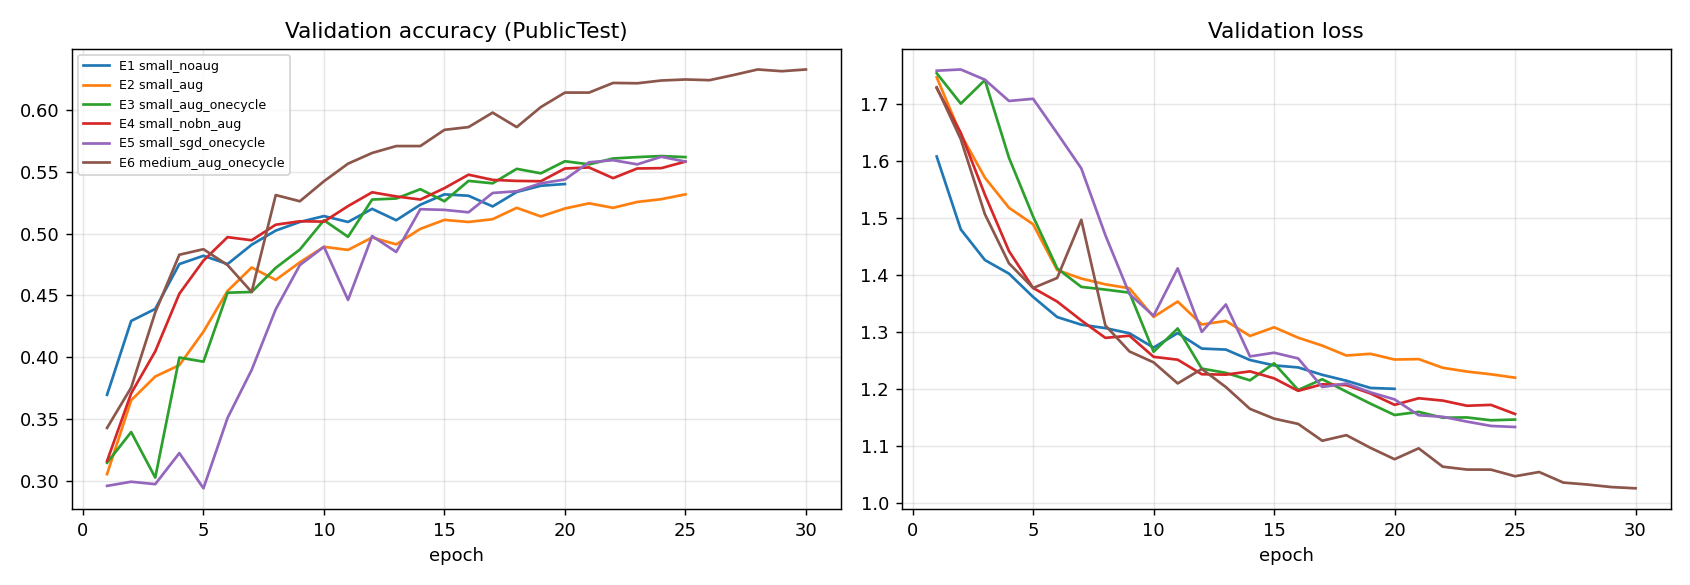

### confusion_matrix.png

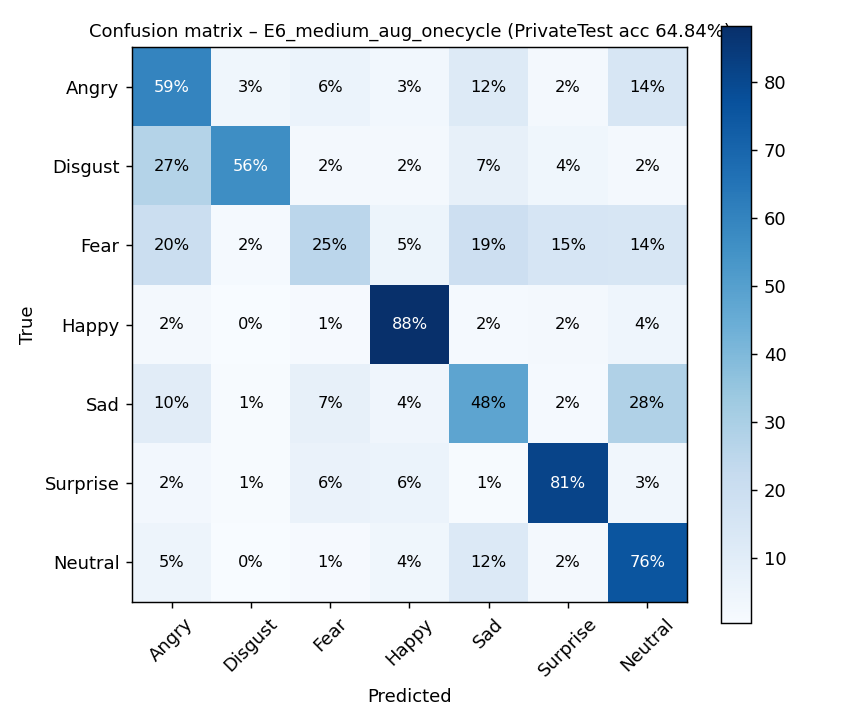

### filters_first_conv.png

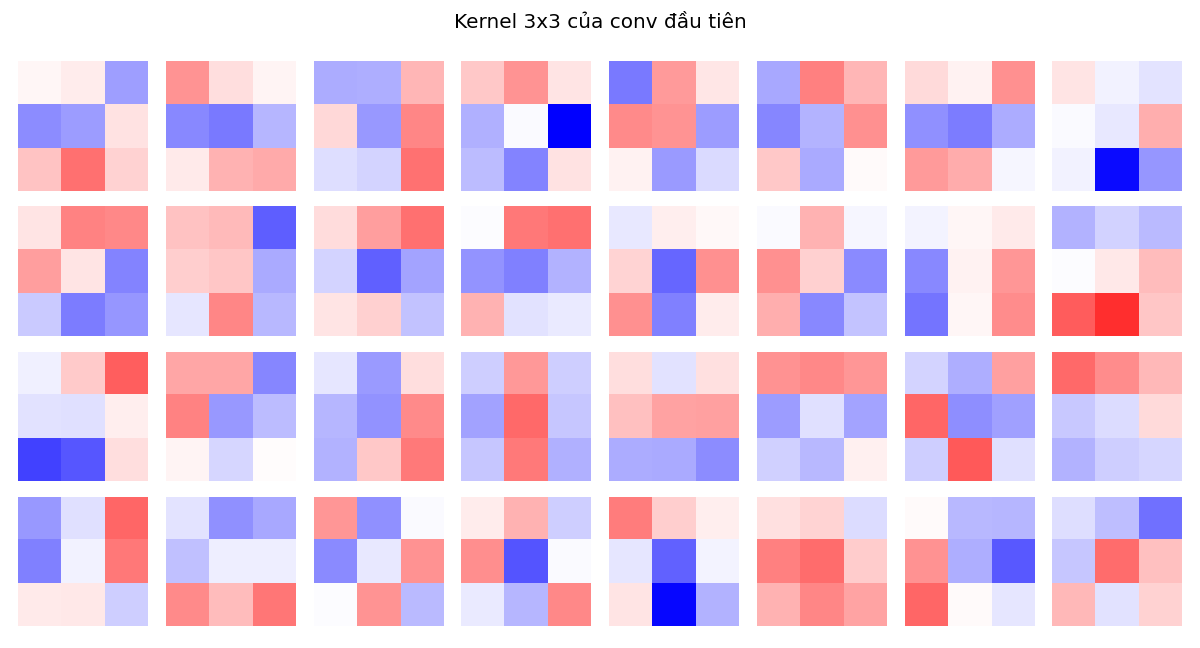

### filters_last_conv_weights.png

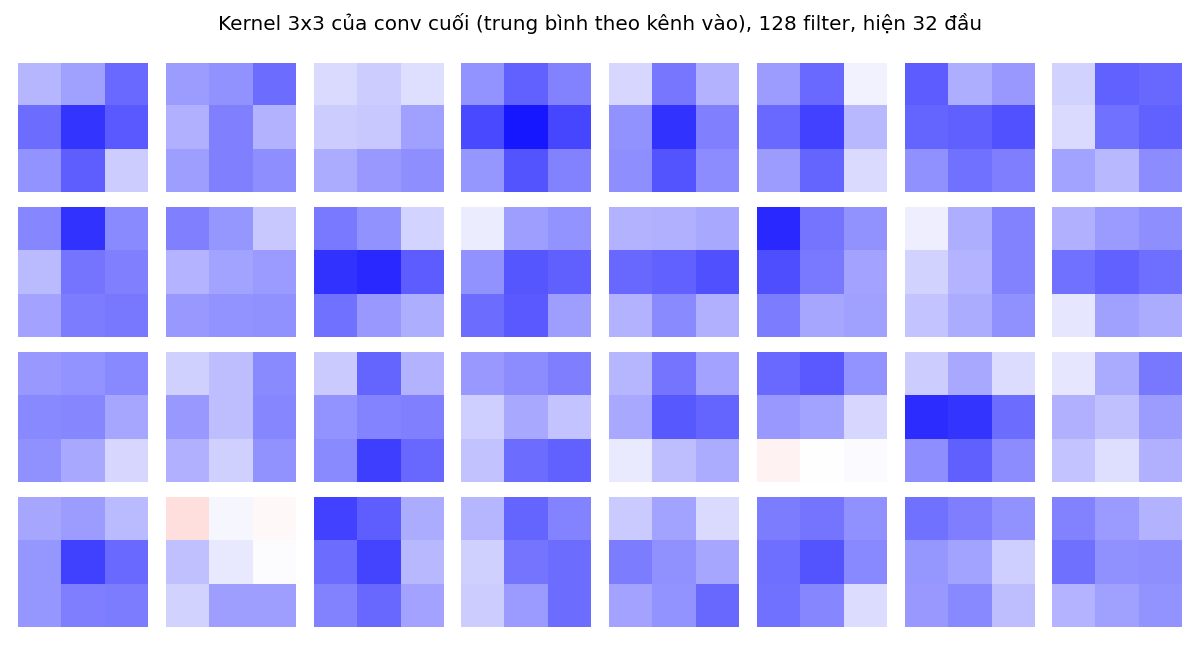

### filters_last_conv_actmax.png

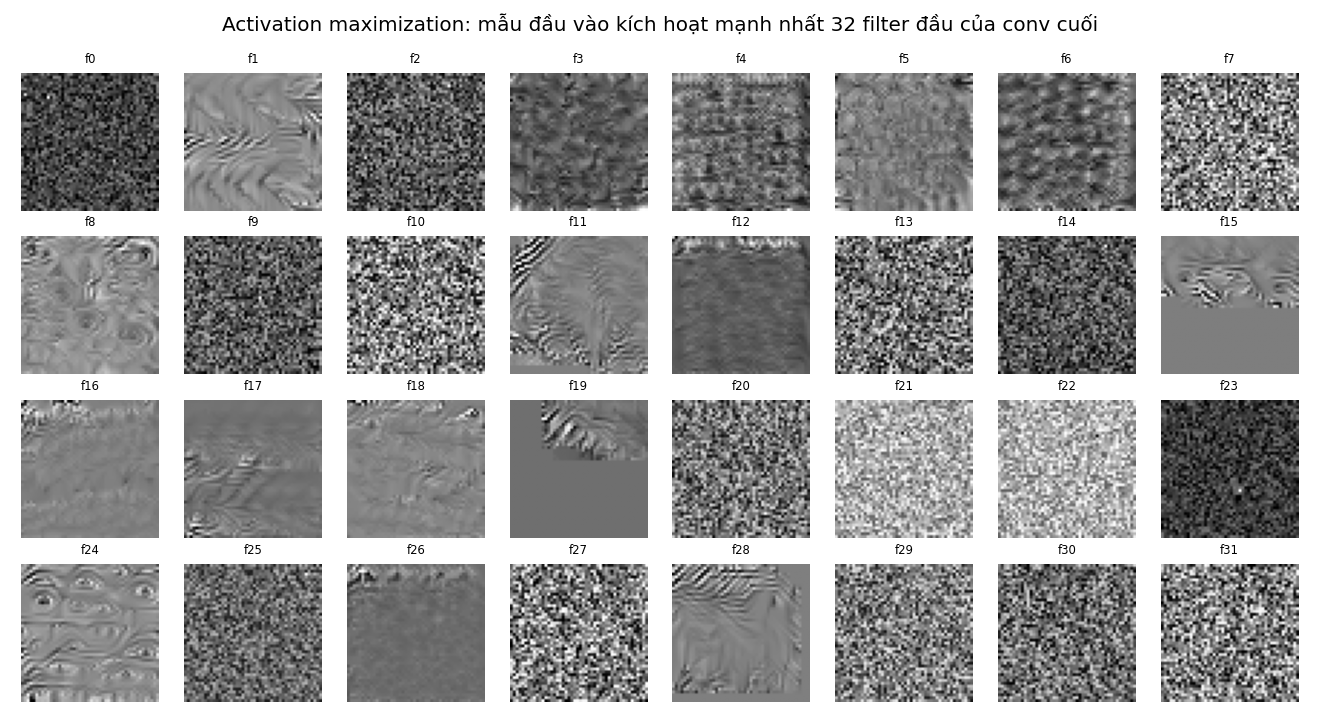

### feature_maps_last_conv.png

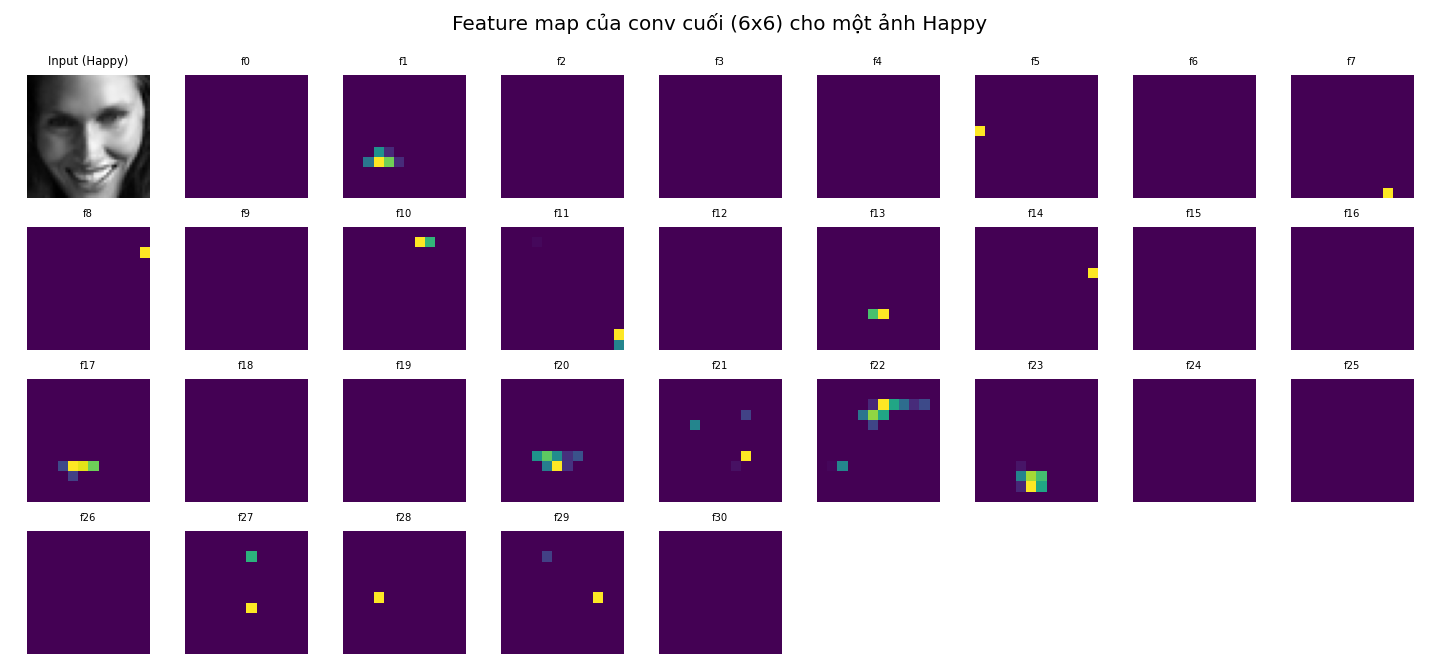

### wrong_cases.png

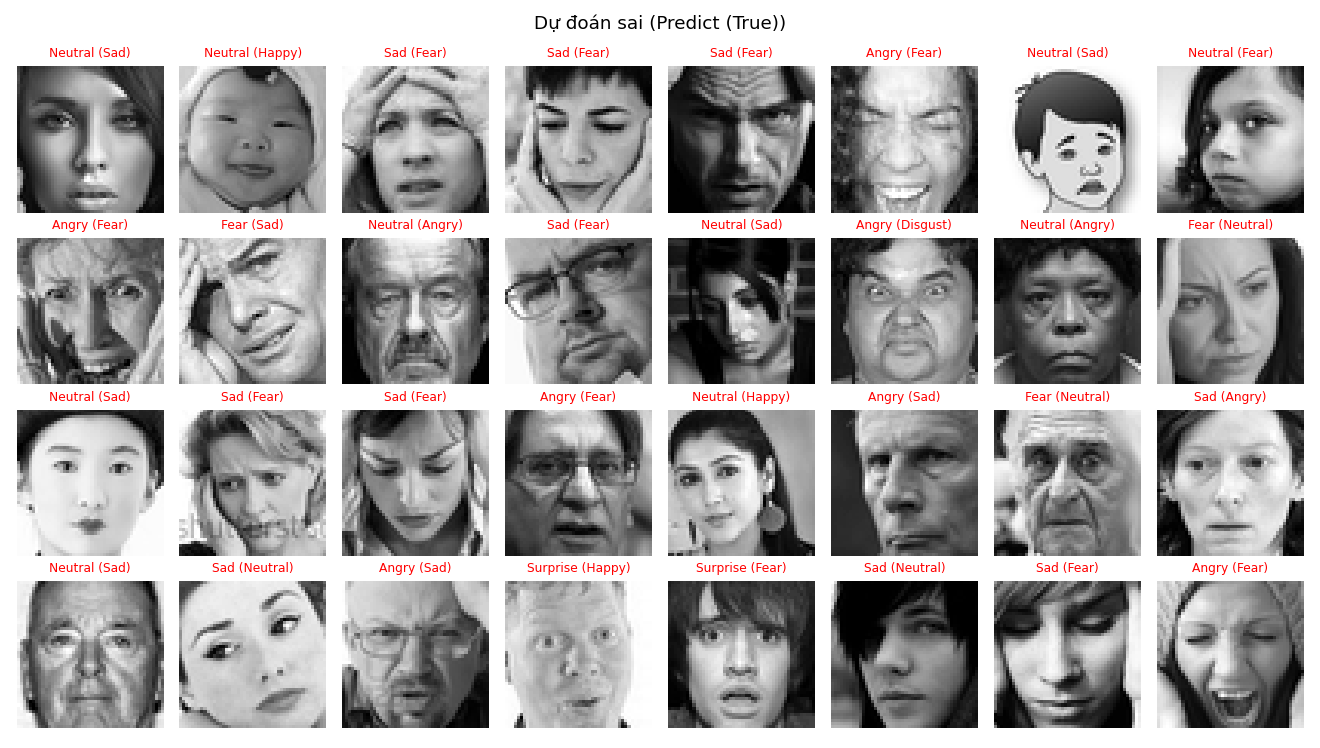

### true_cases.png

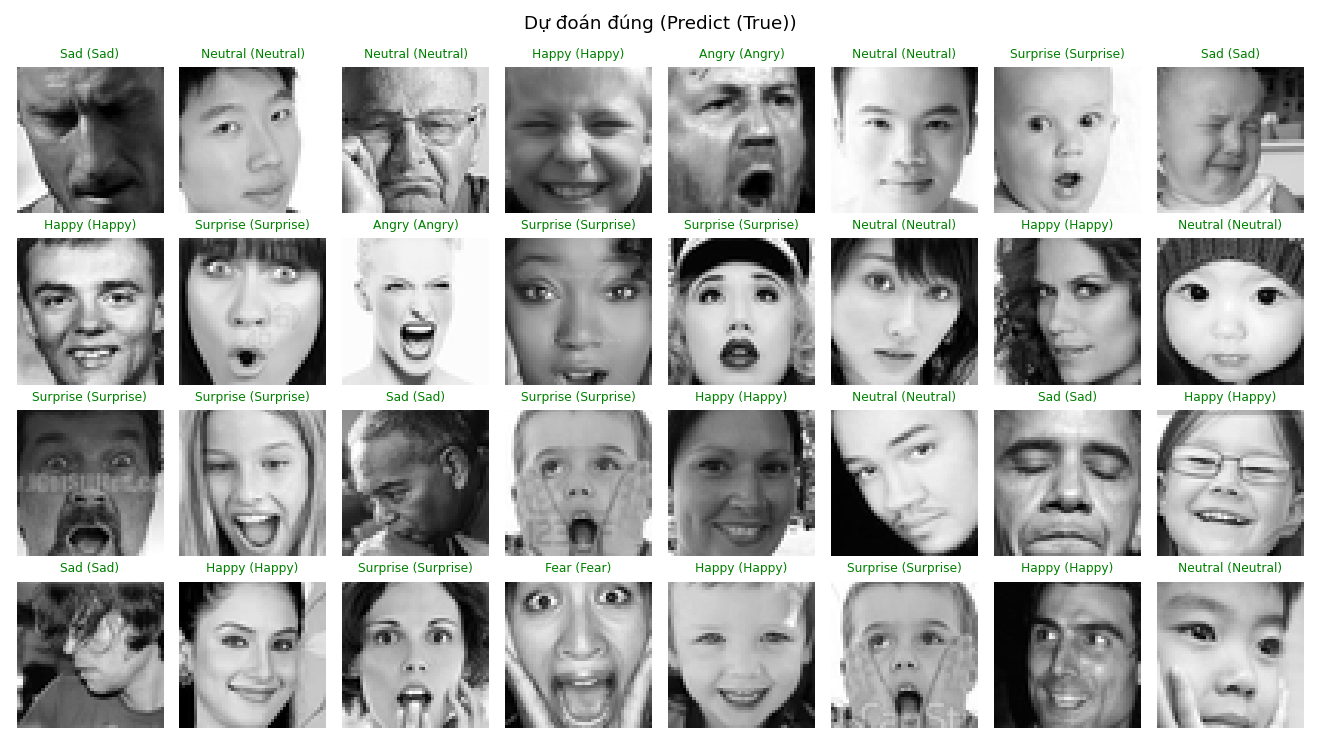

In [8]:
import csv, json, os
from IPython.display import Image, Markdown, display

log_path = LOG_PATH
report_path = REPORT_PATH
fig_dir = FIG_DIR


def show_results():
    display(Markdown("## Experiment log"))
    with open(log_path, encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))
    if rows:
        header, body = rows[0], rows[1:]
        lines = ["| " + " | ".join(header) + " |",
                 "| " + " | ".join(["---"] * len(header)) + " |"]
        lines += ["| " + " | ".join(r) + " |" for r in body]
        display(Markdown("\n".join(lines)))
        old_log = os.path.join(EXP_DIR, "experiment_log.csv")
        if os.path.exists(old_log):
            with open(old_log, encoding="utf-8-sig") as f:
                old_rows = list(csv.reader(f))
            old_header, old_body = old_rows[0], old_rows[1:]
            old_by = {r[0]: dict(zip(old_header, r)) for r in old_body}
            new_by = {r[0]: dict(zip(header, r)) for r in body}
            key = "Test acc (PrivateTest)"
            print("So sánh Test acc (PrivateTest): cũ -> mới")
            for name in sorted(set(old_by) | set(new_by)):
                o = old_by.get(name, {}).get(key)
                n = new_by.get(name, {}).get(key)
                if o and n:
                    print(f"{name:32s} {float(o)*100:5.2f}% -> {float(n)*100:5.2f}% ({float(n)-float(o):+.2%})")
                else:
                    print(f"{name:32s} old={o} new={n}")
        else:
            print("Không có experiment_log.csv gốc để so sánh.")

    report = json.load(open(report_path))
    display(Markdown(f"## Best: `{report['best']}` — PrivateTest accuracy **{report['test_acc'] * 100:.2f}%**"))
    print(f"accuracy = {report['report'].get('accuracy', 0):.4f}")
    for cls, m in report["report"].items():
        if isinstance(m, dict):
            print(f"{cls:12s} precision={m['precision']:.3f} recall={m['recall']:.3f} "
                  f"f1={m['f1-score']:.3f} support={int(m['support'])}")

    for fname in ["compare_val.png", "confusion_matrix.png", "filters_first_conv.png",
                  "filters_last_conv_weights.png", "filters_last_conv_actmax.png",
                  "feature_maps_last_conv.png", "wrong_cases.png", "true_cases.png"]:
        path = os.path.join(fig_dir, fname)
        if os.path.exists(path):
            display(Markdown(f"### {fname}"))
            display(Image(filename=path))


if os.path.exists(log_path) and os.path.exists(report_path):
    show_results()
else:
    print("No analysis outputs found. Set RUN_ANALYSIS=True and rerun the analysis cell.")


## 9. Đóng gói kết quả

In [9]:
import os, zipfile
from IPython.display import FileLink, display

zip_path = os.path.join(OUT_DIR, "fer2013_results.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name in ["runs", "figures", "experiment_log.csv", "best_report.json"]:
        path = os.path.join(OUT_DIR, name)
        if os.path.isdir(path):
            for root, _, files in os.walk(path):
                for f in files:
                    fp = os.path.join(root, f)
                    z.write(fp, os.path.relpath(fp, OUT_DIR))
        elif os.path.exists(path):
            z.write(path, name)

print("Archive:", zip_path, os.path.getsize(zip_path), "bytes")
try:
    display(FileLink(zip_path))
except Exception as e:
    print("Open manually:", zip_path, "|", e)


Archive: c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\outputs_long_sqrt\fer2013_results.zip 18544709 bytes


c:\Users\kelac\Downloads\HOCTAP\deeplearning\Thuchanhvabaitapdeeplearning\baitaplon0215%\BT02\Code_FER2013\outputs_long_sqrt\fer2013_results.zip